# DM2 - Questions 1, 2 et 3

Ce notebook teste la classification binaire chiffre à chiffre en utilisant une méthode adaboost. Pour chaque paire de chiffre on entraine **Adaboost** avec trois classifieurs faibles : 
- stump
- perceptron
- arbre de décision de profondeurs 5, 7, 10 et 15

Dans un premier temps, on a fait les entrainements dans les **784 pixels de l'image** puis en utilisant un **embedding** : les 64 neuronnes << 784 de la couche caché d'un MLP.

Chaque entraînement est fait dans deux espaces d'entrée :



Les modèles sont comparés sur leur **F1 score** (F1 macro : moyenne du F1 de chacun des deux chiffres de la paire).

En raiso du grand nombre de modèle traité dans ce notebook, celui ci est prévu pour être éxécuté sur un machine virtuelle.

Chaque résultat est enregistré dans le dossier resultats/ afin de reproduire les figures facilement.

Pour le MLP utilisé lors de l'embedding, on a utilisé le **MLPRegressor** de scikit-learn. On a utilisé un chatbot pour implémenter ce MLP.

## 1. Imports et réglages

In [3]:
# Si pas déjà installé 
%pip install -q numpy pandas matplotlib scikit-learn joblib optuna

Note: you may need to restart the kernel to use updated packages.


In [4]:
import os
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.datasets import fetch_openml
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Perceptron
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.tree import DecisionTreeClassifier

random_seed = 1234

In [5]:
# Paires étudiées : toutes les combinaisons de 2 chiffres parmi les 10 chiffres (0 à 9)
CHIFFRES = list(range(0, 10))
PAIRES = [(a, b) for a in CHIFFRES for b in CHIFFRES if a < b]

# Profondeurs des arbres de décision
PROFONDEURS = [5, 7, 10, 15]

# Nombre d'étapes de boosting
NB_ETAPES = 500
NB_ETAPES_ARBRES = NB_ETAPES    

# Recherche Optuna pour le perceptron (perceptron seul, sans boosting)
NB_ESSAIS_OPTUNA = 20

# Embedding (question 3) : MLP auto-associateur 784 -> TAILLE_EMBEDDING -> 784
TAILLE_EMBEDDING = 64
NB_EPOQUES_AUTOENCODEUR = 30    # nombre maximal d'époques (l'entraînement s'arrête avant s'il ne progresse plus)

# Calcul
N_JOBS = -1                
FORCER_RECALCUL = False    # Si les résultats existent déjà, les réutiliser plutôt que de recalculer. Mettre à True pour recalculer.

DOSSIER_RESULTATS = "resultats"
DOSSIER_MODELES = "modeles"
DOSSIER_FIGURES = "figures/taches"

ESPACES = ["Pixels", "Embedding"]

TACHES = [{"nom": f"{a}_{b}", "a": a, "b": b, "etiquettes": [str(a), str(b)]} for (a, b) in PAIRES]

def reglages_tache(tache):
    """Réglages dont dépend le résultat d'une tâche. Ils sont enregistrés avec le résultat :
    si l'un d'eux change, la tâche est recalculée au lieu de réutiliser un ancien résultat."""
    return {"METRIQUE": "f1_macro",
            "NB_ETAPES": NB_ETAPES, "NB_ETAPES_ARBRES": NB_ETAPES_ARBRES,
            "PROFONDEURS": list(PROFONDEURS), "NB_ESSAIS_OPTUNA": NB_ESSAIS_OPTUNA,
            "TAILLE_EMBEDDING": TAILLE_EMBEDDING, "NB_EPOQUES_AUTOENCODEUR": NB_EPOQUES_AUTOENCODEUR}

print(len(TACHES), "tâches :", [t["nom"] for t in TACHES])

45 tâches : ['0_1', '0_2', '0_3', '0_4', '0_5', '0_6', '0_7', '0_8', '0_9', '1_2', '1_3', '1_4', '1_5', '1_6', '1_7', '1_8', '1_9', '2_3', '2_4', '2_5', '2_6', '2_7', '2_8', '2_9', '3_4', '3_5', '3_6', '3_7', '3_8', '3_9', '4_5', '4_6', '4_7', '4_8', '4_9', '5_6', '5_7', '5_8', '5_9', '6_7', '6_8', '6_9', '7_8', '7_9', '8_9']


## 2. Données

In [6]:
mnist = fetch_openml('mnist_784', version=1, data_home="data", as_frame=False, parser='liac-arff')

Xtrain = (mnist.data[0:60000] / 255.0).astype(np.float32)
Ytrain = mnist.target[0:60000].astype(int)

Xtest = (mnist.data[60000:70000] / 255.0).astype(np.float32)
Ytest = mnist.target[60000:70000].astype(int)

print(Xtrain.shape, Xtest.shape)

(60000, 784) (10000, 784)


## 3. Embedding : MLP auto-associateur (question 3)

On entraîne un perceptron multi-couches à **une couche cachée de 64 neurones** à reproduire son entrée : 784 pixels en entrée, 784 pixels en sortie. Les 64 neuronnes de la couches caché permet de synthétiser l'image. C'est cet espace qu'on va réutiliser lors de l'embedding.

Le MLP est entraîné une seule fois, sur toutes les images d'entraînement et sans utiliser les étiquettes. Il est enregistré dans `modeles/` pour ne pas être réentraîné à chaque exécution.

In [7]:
os.makedirs(DOSSIER_MODELES, exist_ok=True)
fichier_autoencodeur = os.path.join(
    DOSSIER_MODELES, f"autoencodeur_{TAILLE_EMBEDDING}_neurones_{NB_EPOQUES_AUTOENCODEUR}_epoques.joblib")

if os.path.exists(fichier_autoencodeur) and not FORCER_RECALCUL:
    autoencodeur = joblib.load(fichier_autoencodeur)
    print("Auto-associateur chargé depuis", fichier_autoencodeur)
else:
    autoencodeur = MLPRegressor(hidden_layer_sizes=(TAILLE_EMBEDDING,), activation="relu",
                                max_iter=NB_EPOQUES_AUTOENCODEUR, random_state=random_seed)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        autoencodeur.fit(Xtrain, Xtrain)
    joblib.dump(autoencodeur, fichier_autoencodeur)
    print("Auto-associateur entraîné et enregistré dans", fichier_autoencodeur)

# Poids de la couche cachée : W a une colonne par neurone caché
W_enc = autoencodeur.coefs_[0].astype(np.float32)        # forme (784, 64)
b_enc = autoencodeur.intercepts_[0].astype(np.float32)   # forme (64,)

def encoder(X):
    """Passe des pixels (784) à l'embedding (64) : activité des neurones cachés."""
    return np.maximum(X @ W_enc + b_enc, 0)

Ztrain = encoder(Xtrain)
Ztest = encoder(Xtest)
print("Embedding :", Ztrain.shape, Ztest.shape)

reconstruction = autoencodeur.predict(Xtest)
print("Erreur quadratique moyenne de reconstruction (test) :", round(float(np.mean((reconstruction - Xtest) ** 2)), 5))

c:\Users\aurel\anaconda3\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator MLPRegressor from version 1.9.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


Auto-associateur chargé depuis modeles\autoencodeur_64_neurones_30_epoques.joblib
Embedding : (60000, 64) (10000, 64)
Erreur quadratique moyenne de reconstruction (test) : 0.00937


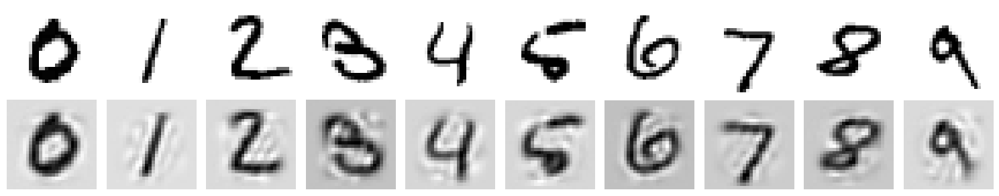

In [8]:
# Contrôle visuel : images d'origine (en haut) et reconstruites par le MLP (en bas)
os.makedirs(DOSSIER_FIGURES, exist_ok=True)
fig, axs = plt.subplots(2, 10, figsize=(15, 3.4))
for j in range(10):
    i = np.flatnonzero(Ytest == j)[0]
    axs[0, j].imshow(Xtest[i].reshape(28, 28), cmap="gray_r")
    axs[1, j].imshow(reconstruction[i].reshape(28, 28), cmap="gray_r")
    axs[0, j].axis("off")
    axs[1, j].axis("off")
plt.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(os.path.join(DOSSIER_FIGURES, "autoencodeur_reconstructions.png"), dpi=110)
plt.show()

In [ ]:
# Prépare les données pour chaque paire de chiffres

def preparer_tache(tache):
    
    a, b = tache["a"], tache["b"]
    idx_train = np.flatnonzero((Ytrain == a) | (Ytrain == b))
    idx_test = np.flatnonzero((Ytest == a) | (Ytest == b))
    y_train = (Ytrain[idx_train] == b).astype(int)
    y_test = (Ytest[idx_test] == b).astype(int)

    return (Xtrain[idx_train], y_train, Xtest[idx_test], y_test, Ztrain[idx_train], Ztest[idx_test])

## 4. Algorithme AdaBoost

Cette section permet de reconstruire l'algorithme adaboost. On décidera par la suite d'utiliser cet algorithme ou le module adaboost classifier de scikit-learn.

In [8]:
def adaboost(X, y, classifieur, nb_etape):

    y_signe = 2*y - 1 # On convertit les labels en {-1, +1}
    n = X.shape[0]
    w = np.ones(n) / n # Initialisation des poids

    classifieurs = []
    alphas = []

    for t in range(nb_etape):
        # On clone le classifieur pour avoir un nouveau modèle à chaque étape
        clf = clone(classifieur)
        clf.fit(X, y, sample_weight=w) # On entraine le classifieur avec les poids

        # On calcule l'erreur du classifieur
        pred = clf.predict(X)
        erreur = np.sum(w * (pred != y)) / np.sum(w)

        # On calcule le poids du classifieur
        alpha = 0.5 * np.log((1 - erreur) / (erreur + 1e-10)) # On ajoute un petit terme pour éviter la division par zéro

        # On met à jour les poids des exemples
        w *= np.exp(-alpha * y_signe * (2*pred - 1))
        w /= np.sum(w) # Normalisation des poids

        classifieurs.append(clf)
        alphas.append(alpha)

    return classifieurs, alphas

def adaboost_predict(X, classifieurs, alphas):
    score = np.zeros(X.shape[0])
    for clf, alpha in zip(classifieurs, alphas):
        score += alpha * (2 * clf.predict(X) - 1)
    return (score > 0).astype(int)

## 5. Évaluation et cartes de saillance

- Après chaque étape de boosting, on calcule la F1 score et on conserve la matrice de confusion.


**Saillance dans l'espace des pixels (question 2)**

- stumps et arbres : pour chaque pixel, somme des importances que lui donnent les arbres, pondérée par leur `alpha` ;
- perceptron : somme des poids des perceptrons, pondérée par leur `alpha`. La carte est signée : positif pousse vers la classe 1, négatif vers la classe 0.

**Saillance depuis l'embedding (question 3)**

Dans l'embedding, un stump ne teste plus un pixel mais un **neurone caché**. On procède en deux temps, comme dans GradCAM :

1. on calcule un **coefficient signé par neurone caché** : positif si une forte activité du neurone pousse vers la classe 1, négatif si elle pousse vers la classe 0. Pour un stump, le signe se lit dans l'arbre (de quel côté du seuil la classe 1 est majoritaire) et le coefficient est son `alpha`. Pour un arbre plus profond, chaque noeud compte avec son importance et son signe. Pour un perceptron, ce sont ses poids ;
2. on **rétropropage** ces coefficients vers les pixels à travers la couche cachée : l'effet d'un pixel sur un neurone est le poids qui les relie, multiplié par la dérivée de l'activation du neurone (pour ReLU : 1 si le neurone est actif, 0 sinon). Cette dérivée est moyennée sur les images de test de la tâche.

La carte obtenue est signée. Pour les stumps et les arbres, on affiche sa valeur absolue, ce qui la rend comparable aux cartes de l'espace des pixels.

In [9]:
def etapes_affichees(n):
    return sorted({e for e in [1, 10, 100, n] if 1 <= e <= n})

def f1(y, pred):
    """F1 macro : moyenne du F1 de chacune des deux classes. Le F1 d'une classe jamais prédite vaut 0."""
    return f1_score(y, pred, labels=[0, 1], average="macro", zero_division=0)

def evaluer(X, y, classifieurs, alphas):
    score = np.zeros(X.shape[0])
    f1_etapes = []
    confusions = {}
    etapes = etapes_affichees(len(classifieurs))
    for t, (clf, alpha) in enumerate(zip(classifieurs, alphas), start=1):
        score += alpha * (2 * clf.predict(X) - 1)
        pred = (score > 0).astype(int)
        f1_etapes.append(f1(y, pred))
        if t in etapes:
            confusions[t] = confusion_matrix(y, pred, labels=[0, 1])
    return np.array(f1_etapes), confusions

def importance_arbres(classifieurs, alphas):
    """Importance de chaque variable d'entrée (pixel ou neurone) pour des stumps ou des arbres."""
    importance = np.zeros(classifieurs[0].n_features_in_)
    for clf, alpha in zip(classifieurs, alphas):
        importance += abs(alpha) * clf.feature_importances_
    return importance

def poids_perceptrons(classifieurs, alphas):
    """Poids signé de chaque variable d'entrée (pixel ou neurone) pour des perceptrons."""
    poids_total = np.zeros(classifieurs[0].n_features_in_)
    for clf, alpha in zip(classifieurs, alphas):
        poids = clf.coef_[0]
        poids_total += alpha * poids / (np.linalg.norm(poids) + 1e-10)
    return poids_total

def importance_signee_arbre(clf):
    """Comme feature_importances_, mais avec un signe : un noeud compte en positif si dépasser son seuil
    augmente la proportion de la classe 1, en négatif sinon."""
    arbre = clf.tree_
    importance = np.zeros(arbre.n_features)
    gain_total = 0.0
    for noeud in range(arbre.node_count):
        gauche, droite = arbre.children_left[noeud], arbre.children_right[noeud]
        if gauche == -1:      # feuille : pas de test
            continue
        gain = (arbre.weighted_n_node_samples[noeud] * arbre.impurity[noeud]
                - arbre.weighted_n_node_samples[gauche] * arbre.impurity[gauche]
                - arbre.weighted_n_node_samples[droite] * arbre.impurity[droite])
        p_gauche = arbre.value[gauche][0, 1] / (arbre.value[gauche][0].sum() + 1e-300)
        p_droite = arbre.value[droite][0, 1] / (arbre.value[droite][0].sum() + 1e-300)
        importance[arbre.feature[noeud]] += gain * np.sign(p_droite - p_gauche)
        gain_total += gain
    return importance / gain_total if gain_total > 0 else importance

def importance_signee_arbres(classifieurs, alphas):
    """Coefficient signé de chaque variable d'entrée pour des stumps ou des arbres boostés."""
    importance = np.zeros(classifieurs[0].n_features_in_)
    for clf, alpha in zip(classifieurs, alphas):
        importance += alpha * importance_signee_arbre(clf)
    return importance

def carte_saillance(classifieurs, alphas, espace, est_perceptron, W, derivee_moyenne):
    if espace == "Pixels":
        valeurs = poids_perceptrons(classifieurs, alphas) if est_perceptron else importance_arbres(classifieurs, alphas)
        return valeurs.reshape(28, 28)

    # Embedding : coefficient signé de chaque neurone caché, puis rétropropagation vers les pixels
    if est_perceptron:
        coefficients = poids_perceptrons(classifieurs, alphas)
    else:
        coefficients = importance_signee_arbres(classifieurs, alphas)
    return (W @ (coefficients * derivee_moyenne)).reshape(28, 28)

## 6. Calcul pour chaque paire de chiffre.

`traiter_tache` fait tout le travail pour une paire de chiffre, dans les deux espaces (pixels puis embedding) : stumps, perceptron, arbres de chaque profondeur.

On utilise optuna pour optimiser les hyperparamètres du perceptron afin de pouvoir faire une comparaison juste entre les différents classifieurs faibles.


Tous les résultats sont enrgistrés  `resultats/`.

In [10]:
def fichier_resultat(tache):
    return os.path.join(DOSSIER_RESULTATS, f"tache_{tache['nom']}.joblib")

def fichier_meilleur(tache):
    return os.path.join(DOSSIER_MODELES, f"meilleur_{tache['nom']}.joblib")

def chercher_perceptron(A_train, y_train):
    """Recherche Optuna des hyperparamètres d'un perceptron seul (sans boosting)."""
    A_app, A_val, y_app, y_val = train_test_split(
        A_train, y_train, test_size=0.2, random_state=random_seed, stratify=y_train)

    # Mêmes poids que ceux qu'AdaBoost donne aux images à sa première étape (1/n chacune).
    # Sans cela, Optuna peut retenir une régularisation qui annule le perceptron une fois dans le boosting.
    poids = np.full(len(y_app), 1 / len(y_app))

    def objectif(trial):
        max_iter = trial.suggest_int("max_iter", 1, 30)
        eta0 = trial.suggest_float("eta0", 0.01, 10, log=True)
        penalty = trial.suggest_categorical("penalty", [None, "l2", "l1"])
        alpha_reg = trial.suggest_float("alpha", 1e-6, 1e-2, log=True)
        perceptron = Perceptron(max_iter=max_iter, tol=None, eta0=eta0,
                                penalty=penalty, alpha=alpha_reg, random_state=random_seed)
        perceptron.fit(A_app, y_app, sample_weight=poids)
        return f1(y_val, perceptron.predict(A_val))

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    etude = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=random_seed))
    etude.optimize(objectif, n_trials=NB_ESSAIS_OPTUNA)
    return etude.best_params, etude.best_value

def traiter_tache(tache, X_train, y_train, X_test, y_test, Z_train, Z_test, W, b):
    resultat = {"tache": tache,
                "reglages": reglages_tache(tache),
                "moyenne_0": X_train[y_train == 0].mean(axis=0).reshape(28, 28),
                "moyenne_1": X_train[y_train == 1].mean(axis=0).reshape(28, 28),
                "modeles": {espace: {} for espace in ESPACES},
                "perceptron_params": {},
                "perceptron_f1_validation": {}}

    # Proportion des images de test pour lesquelles chaque neurone caché est actif (dérivée moyenne de ReLU)
    derivee_moyenne = ((X_test @ W + b) > 0).mean(axis=0)

    donnees = {"Pixels": (X_train, X_test), "Embedding": (Z_train, Z_test)}
    meilleur = None

    for espace in ESPACES:
        A_train, A_test = donnees[espace]

        # Liste des classifieurs faibles : (nom, classifieur, est_perceptron, nombre d'étapes)
        faibles = [("Stump", DecisionTreeClassifier(max_depth=1, random_state=random_seed), False, NB_ETAPES)]

        p, f1_val = chercher_perceptron(A_train, y_train)
        resultat["perceptron_params"][espace] = p
        resultat["perceptron_f1_validation"][espace] = f1_val
        faibles.append(("Perceptron",
                        Perceptron(max_iter=p["max_iter"], tol=None, eta0=p["eta0"], penalty=p["penalty"],
                                   alpha=p["alpha"], random_state=random_seed), True, NB_ETAPES))

        for prof in PROFONDEURS:
            faibles.append((f"Arbre prof. {prof}",
                            DecisionTreeClassifier(max_depth=prof, random_state=random_seed), False, NB_ETAPES_ARBRES))

        for nom, faible, est_perceptron, nb_etapes in faibles:
            debut = time.time()
            clfs, als = adaboost(A_train, y_train, faible, nb_etape=nb_etapes)
            duree = time.time() - debut
            f1_test, confusions = evaluer(A_test, y_test, clfs, als)
            f1_train, _ = evaluer(A_train, y_train, clfs, als)
            resultat["modeles"][espace][nom] = {
                "f1_test": f1_test, "f1_train": f1_train, "confusions": confusions,
                "alphas": np.array(als), "duree_s": duree,
                "saillance": carte_saillance(clfs, als, espace, est_perceptron, W, derivee_moyenne)}

            if meilleur is None or f1_test[-1] > meilleur["f1_test"]:
                meilleur = {"tache": tache, "espace": espace, "nom_modele": nom, "f1_test": f1_test[-1],
                            "classifieurs": clfs, "alphas": als}

    resultat["meilleur"] = {cle: meilleur[cle] for cle in ["espace", "nom_modele", "f1_test"]}

    os.makedirs(DOSSIER_MODELES, exist_ok=True)
    joblib.dump(meilleur, fichier_meilleur(tache), compress=3)
    os.makedirs(DOSSIER_RESULTATS, exist_ok=True)
    joblib.dump(resultat, fichier_resultat(tache))
    return tache["nom"]

## 7. Lancement des calculs
Le calcul de cette cellule est très long, c'est pour ça qu'on a utilisé une vm pour l'éxécution et qu'on stocke au fur et à mesure les résultats. Si les résultats ont déjà été calculé on ne recommence pas le calcul.

In [11]:
def resultat_a_jour(tache):
    """Vrai si la tâche a déjà été calculée avec les réglages actuels."""
    if FORCER_RECALCUL or not (os.path.exists(fichier_resultat(tache)) and os.path.exists(fichier_meilleur(tache))):
        return False
    return joblib.load(fichier_resultat(tache)).get("reglages") == reglages_tache(tache)

def empecher_veille(actif):
    """Sous Windows, demande au système de ne pas se mettre en veille tout seul pendant le calcul."""
    if os.name == "nt":
        import ctypes
        ES_CONTINUOUS, ES_SYSTEM_REQUIRED = 0x80000000, 0x00000001
        ctypes.windll.kernel32.SetThreadExecutionState(ES_CONTINUOUS | (ES_SYSTEM_REQUIRED if actif else 0))

a_faire = [t for t in TACHES if not resultat_a_jour(t)]
print(len(a_faire), "tâche(s) à calculer sur", len(TACHES))

if a_faire:
    empecher_veille(True)
    try:
        Parallel(n_jobs=N_JOBS, verbose=10)(
            delayed(traiter_tache)(t, *preparer_tache(t), W_enc, b_enc) for t in a_faire)
    finally:
        empecher_veille(False)

resultats = {t["nom"]: joblib.load(fichier_resultat(t)) for t in TACHES}
NOMS_MODELES = list(resultats[TACHES[0]["nom"]]["modeles"]["Pixels"])
print("Résultats chargés pour", len(resultats), "tâches. Modèles :", NOMS_MODELES)

45 tâche(s) à calculer sur 45


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 16 concurrent workers.


/tmp/ipykernel_4350/3905817371.py:53: RuntimeWarning: invalid value encountered in divide


/tmp/ipykernel_4350/3905817371.py:53: RuntimeWarning: invalid value encountered in divide


/tmp/ipykernel_4350/3905817371.py:53: RuntimeWarning: invalid value encountered in divide


/tmp/ipykernel_4350/3905817371.py:53: RuntimeWarning: invalid value encountered in divide


... (216 outputs left out)

/tmp/ipykernel_4350/3905817371.py:53: RuntimeWarning: invalid value encountered in divide


/tmp/ipykernel_4350/3905817371.py:51: RuntimeWarning: invalid value encountered in scalar add


[Parallel(n_jobs=-1)]: Done  45 out of  45 | elapsed: 306.9min finished


Résultats chargés pour 45 tâches. Modèles : ['Stump', 'Perceptron', 'Arbre prof. 5', 'Arbre prof. 7', 'Arbre prof. 10', 'Arbre prof. 15']


A la fin de cette cellule, les 45 paires de chiffres ont été testé avec les 3 classifieurs faibles utilisés.

## 8. Vue globale des résultats

### F1 score final (test) pour chaque tâche, chaque espace et chaque classifieur faible

In [12]:
tableau = pd.DataFrame(
    {(espace, nom): {t["nom"]: resultats[t["nom"]]["modeles"][espace][nom]["f1_test"][-1] for t in TACHES}
     for espace in ESPACES for nom in NOMS_MODELES})
tableau.index.name = "Tâche"

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 50)
display(tableau.round(4))

print("F1 moyen sur toutes les tâches :")
display(tableau.mean().unstack(0)[ESPACES].loc[NOMS_MODELES].round(4))

durees = pd.DataFrame(
    {(espace, nom): {t["nom"]: resultats[t["nom"]]["modeles"][espace][nom]["duree_s"] for t in TACHES}
     for espace in ESPACES for nom in NOMS_MODELES})
print("Temps d'entraînement moyen par tâche (secondes) :")
display(durees.mean().unstack(0)[ESPACES].loc[NOMS_MODELES].round(1))

Pixels                                                        \
        Stump Perceptron Arbre prof. 5 Arbre prof. 7 Arbre prof. 10   
Tâche                                                                 
0_1    0.9995     0.9990        0.9995        0.9967         0.9962   
0_2    0.9915     0.9886        0.9975        0.9950         0.9955   
0_3    0.9950     0.9925        0.9995        0.9990         0.9889   
0_4    0.9990     0.9964        0.9995        0.9995         0.9883   
0_5    0.9920     0.9818        0.9973        0.9979         0.9979   
0_6    0.9897     0.9850        0.9943        0.9954         0.9948   
0_7    0.9965     0.9960        0.9985        0.9985         0.9880   
0_8    0.9923     0.9862        0.9949        0.9944         0.9939   
0_9    0.9920     0.9925        0.9960        0.9955         0.9844   
1_2    0.9940     0.9894        0.9977        0.9977         0.9972   
1_3    0.9963     0.9925        0.9995        0.9977         0.9977   
1_4    0.9986     0.9986        0.9995        0.9995         0.9953   
1_5    0.9960     0.9915        0.9995        0.9995         0.9990   
1_6    0.9981     0.9986        0.9986        0.9981         0.9913   
1_7    0.9958     0.9926        0.9968        0.9968         0.9861   
1_8    0.9943     0.9876        0.9995        0.9990         0.9990   
1_9    0.9977     0.9934        0.9972        0.9981         0.9874   
2_3    0.9770     0.9652        0.9956        0.9971         0.9946   
2_4    0.9836     0.9801        0.9975        0.9970         0.9965   
2_5    0.9838     0.9749        1.0000        1.0000         0.9990   
2_6    0.9864     0.9774        0.9970        0.9975         0.9955   
2_7    0.9801     0.9743        0.9913        0.9913         0.9893   
2_8    0.9801     0.9726        0.9970        0.9975         0.9955   
2_9    0.9873     0.9814        0.9956        0.9951         0.9951   
3_4    0.9930     0.9925        0.9990        0.9990         0.9985   
3_5    0.9609     0.9504        0.9947        0.9968         0.9937   
3_6    0.9949     0.9944        0.9990        0.9990         0.9990   
3_7    0.9882     0.9814        0.9971        0.9951         0.9946   
3_8    0.9677     0.9566        0.9965        0.9960         0.9940   
3_9    0.9782     0.9723        0.9950        0.9936         0.9921   
4_5    0.9872     0.9898        1.0000        1.0000         1.0000   
4_6    0.9918     0.9897        0.9969        0.9964         0.9969   
4_7    0.9900     0.9861        0.9995        0.9990         0.9985   
4_8    0.9939     0.9913        0.9980        0.9969         0.9985   
4_9    0.9719     0.9613        0.9920        0.9900         0.9894   
5_6    0.9767     0.9751        0.9930        0.9940         0.9935   
5_7    0.9921     0.9880        0.9990        0.9990         0.9990   
5_8    0.9721     0.9528        0.9962        0.9957         0.9946   
5_9    0.9815     0.9789        0.9968        0.9968         0.9963   
6_7    0.9985     0.9980        0.9985        0.9990         0.9879   
6_8    0.9896     0.9860        0.9928        0.9928         0.9917   
6_9    0.9964     0.9964        0.9990        0.9995         0.9807   
7_8    0.9930     0.9815        0.9985        0.9980         0.9975   
7_9    0.9750     0.9504        0.9941        0.9966         0.9931   
8_9    0.9783     0.9733        0.9950        0.9945         0.9909   

                     Embedding                                         \
      Arbre prof. 15     Stump Perceptron Arbre prof. 5 Arbre prof. 7   
Tâche                                                                   
0_1           0.9952    0.9995     0.9986        0.9995        0.9990   
0_2           0.9816    0.9891     0.9940        0.9945        0.9940   
0_3           0.9889    0.9940     0.9905        0.9980        0.9985   
0_4           0.9893    0.9964     0.9985        0.9985        0.9985   
0_5           0.9684    0.9898     0.9882        0.9963        0.9963   
0_6           

F1 moyen sur toutes les tâches :


,Pixels,Embedding
Stump,0.9882,0.9857
Perceptron,0.9830,0.9831
Arbre prof. 5,0.9971,0.9944
Arbre prof. 7,0.9969,0.9947
Arbre prof. 10,0.9939,0.9938
Arbre prof. 15,0.9804,0.9886


Temps d'entraînement moyen par tâche (secondes) :


,Pixels,Embedding
Stump,175.2,52.0
Perceptron,197.5,23.5
Arbre prof. 5,702.5,230.1
Arbre prof. 7,896.2,305.9
Arbre prof. 10,1093.2,398.7
Arbre prof. 15,1322.9,497.3


### Meilleur classifieur de chaque tâche

In [13]:
meilleurs = pd.DataFrame.from_dict({t["nom"]: resultats[t["nom"]]["meilleur"] for t in TACHES}, orient="index")
meilleurs["f1_test"] = meilleurs["f1_test"].astype(float).round(4)
meilleurs["fichier"] = [os.path.basename(fichier_meilleur(t)) for t in TACHES]
meilleurs.index.name = "Tâche"
display(meilleurs)

print("Nombre de tâches gagnées par chaque modèle :")
display(meilleurs.groupby(["espace", "nom_modele"]).size().to_frame("tâches gagnées"))

,espace,nom_modele,f1_test,fichier
Tâche,,,,
0_1,Embedding,Stump,0.9995,meilleur_0_1.joblib
0_2,Pixels,Arbre prof. 5,0.9975,meilleur_0_2.joblib
0_3,Pixels,Arbre prof. 5,0.9995,meilleur_0_3.joblib
0_4,Pixels,Arbre prof. 5,0.9995,meilleur_0_4.joblib
0_5,Pixels,Arbre prof. 7,0.9979,meilleur_0_5.joblib
0_6,Pixels,Arbre prof. 7,0.9954,meilleur_0_6.joblib
0_7,Pixels,Arbre prof. 5,0.9985,meilleur_0_7.joblib
0_8,Pixels,Arbre prof. 5,0.9949,meilleur_0_8.joblib
0_9,Pixels,Arbre prof. 5,0.9960,meilleur_0_9.joblib


Nombre de tâches gagnées par chaque modèle :


tâches gagnées
espace    nom_modele                    
Embedding Arbre prof. 5                1
          Arbre prof. 7                1
          Stump                        1
Pixels    Arbre prof. 10               1
          Arbre prof. 5               28
          Arbre prof. 7               12
          Perceptron                   1

## 9. Résultats détaillés : matrices de confusion, courbes et cartes de saillance

Pour chaque paire de chiffre étudié, on a quatre figures :

1. les matrices de confusion dans l'espace des pixels : une ligne par classifieur faible, une colonne par nombre d'étapes de boosting ;
2. les mêmes matrices dans l'embedding ;
3. les courbes du F1 score en fonction du nombre d'étapes (trait plein : test, pointillés : train) ;
4. les cartes de saillance : images moyennes des deux classes, puis une carte par classifieur faible, pour les pixels (haut) et l'embedding (bas).



In [17]:
def figure_confusions(tache, espace):
    res = resultats[tache["nom"]]
    modeles = res["modeles"][espace]
    nb_col = max(len(modeles[nom]["confusions"]) for nom in NOMS_MODELES)
    fig, axs = plt.subplots(len(NOMS_MODELES), nb_col, figsize=(2.7 * nb_col, 2.6 * len(NOMS_MODELES)), squeeze=False)
    for ax in axs.flat:
        ax.axis("off")

    for i, nom in enumerate(NOMS_MODELES):
        for j, (etape, cm) in enumerate(sorted(modeles[nom]["confusions"].items())):
            ax = axs[i, j]
            ax.axis("on")
            f1_etape = modeles[nom]["f1_test"][etape - 1]
            ConfusionMatrixDisplay(cm, display_labels=tache["etiquettes"]).plot(ax=ax, cmap="Blues", colorbar=False)
            ax.set_title(f"{nom} - {etape} étapes\nF1 {f1_etape:.3f}", fontsize=9)
            ax.set_xlabel("Prédit", fontsize=8)
            ax.set_ylabel("Vrai", fontsize=8)

    fig.suptitle(f"Matrices de confusion {tache['nom']} - {espace}", fontsize=15)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    fig.savefig(os.path.join(DOSSIER_FIGURES, f"confusion_{tache['nom']}_{espace}.png"), dpi=90)
    plt.show()

def figure_courbes(tache):
    res = resultats[tache["nom"]]
    fig, axs = plt.subplots(1, len(ESPACES), figsize=(6.8 * len(ESPACES), 4.4), squeeze=False)

    for ax, espace in zip(axs[0], ESPACES):
        for k, nom in enumerate(NOMS_MODELES):
            m = res["modeles"][espace][nom]
            etapes = np.arange(1, len(m["f1_test"]) + 1)
            ax.plot(etapes, m["f1_test"], color=f"C{k}", label=nom)
            ax.plot(etapes, m["f1_train"], color=f"C{k}", linestyle=":", alpha=0.6)
        ax.set_xscale("log")
        ax.set_xlabel("Nombre d'étapes de boosting")
        ax.set_ylabel("F1 score")
        ax.set_title(f"{espace} (plein : test, pointillés : train)")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)

    fig.suptitle(f"Courbes {tache['nom']}", fontsize=15)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    fig.savefig(os.path.join(DOSSIER_FIGURES, f"courbes_{tache['nom']}.png"), dpi=100)
    plt.show()

def figure_saillance(tache):
    res = resultats[tache["nom"]]
    e0, e1 = tache["etiquettes"]
    nb = 2 + len(NOMS_MODELES)
    fig, axs = plt.subplots(len(ESPACES), nb, figsize=(2.6 * nb, 3.3 * len(ESPACES)), squeeze=False)

    axs[0, 0].imshow(res["moyenne_0"], cmap="gray_r")
    axs[0, 0].set_title(f"Moyenne des {e0}", fontsize=9)
    axs[0, 1].imshow(res["moyenne_1"], cmap="gray_r")
    axs[0, 1].set_title(f"Moyenne des {e1}", fontsize=9)

    for i, espace in enumerate(ESPACES):
        for ax, nom in zip(axs[i, 2:], NOMS_MODELES):
            carte = res["modeles"][espace][nom]["saillance"]
            if nom == "Perceptron":
                vmax = np.abs(carte).max() + 1e-12
                ax.imshow(carte, cmap="bwr", vmin=-vmax, vmax=vmax)
            else:
                ax.imshow(np.abs(carte), cmap="hot")
            ax.set_title(f"{espace} - {nom}", fontsize=9)

    for ax in axs.flat:
        ax.set_xticks([])
        ax.set_yticks([])
    for ax in axs[1:, :2].flat:
        ax.axis("off")

    fig.suptitle(f"Cartes de saillance {tache['nom']}   (perceptron : rouge pousse vers {e1}, bleu vers {e0})", fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.94], h_pad=2.0)
    fig.savefig(os.path.join(DOSSIER_FIGURES, f"saillance_{tache['nom']}.png"), dpi=100)
    plt.show()

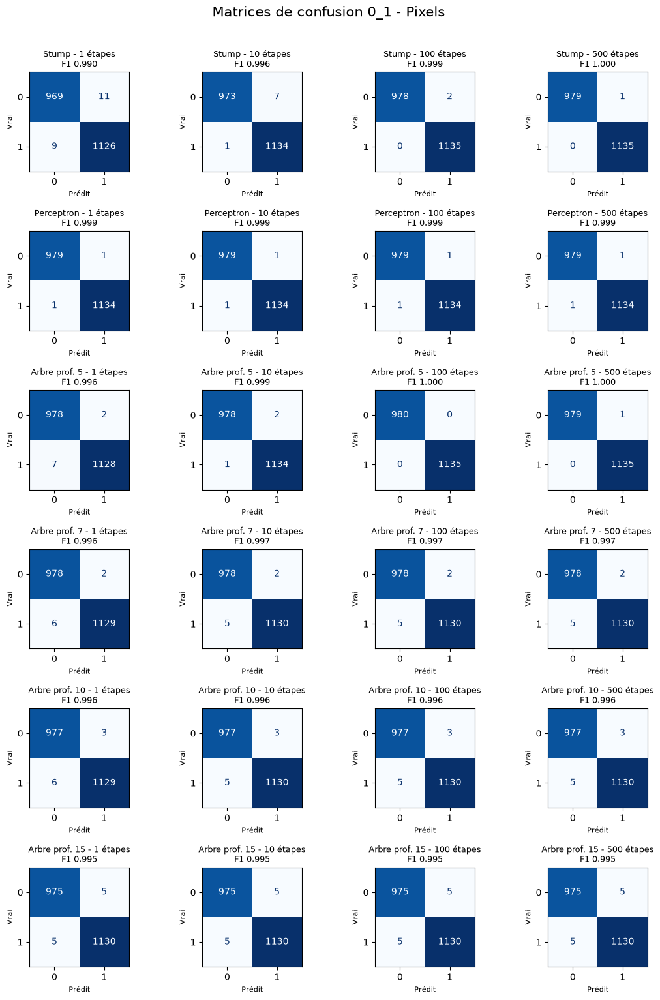

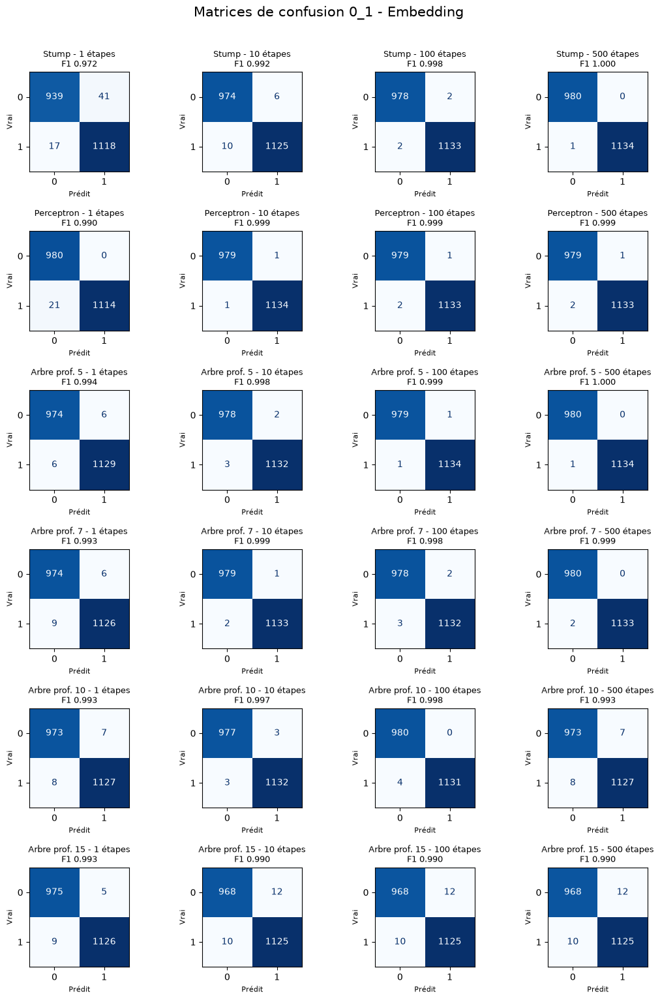

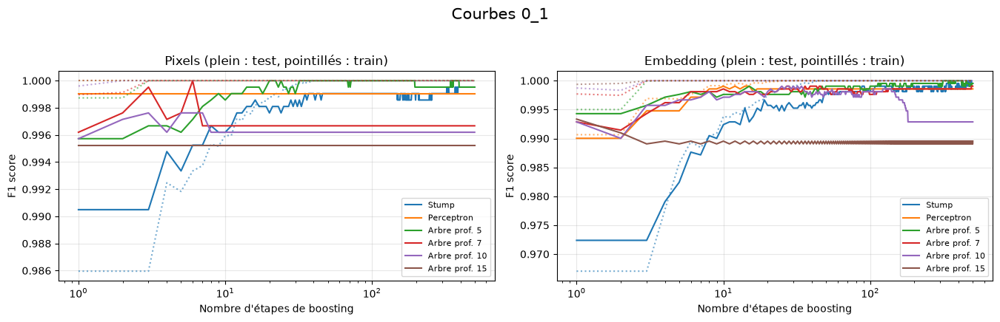

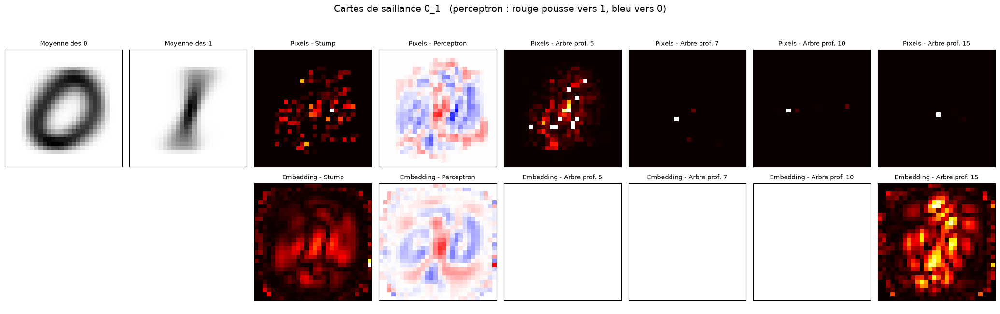

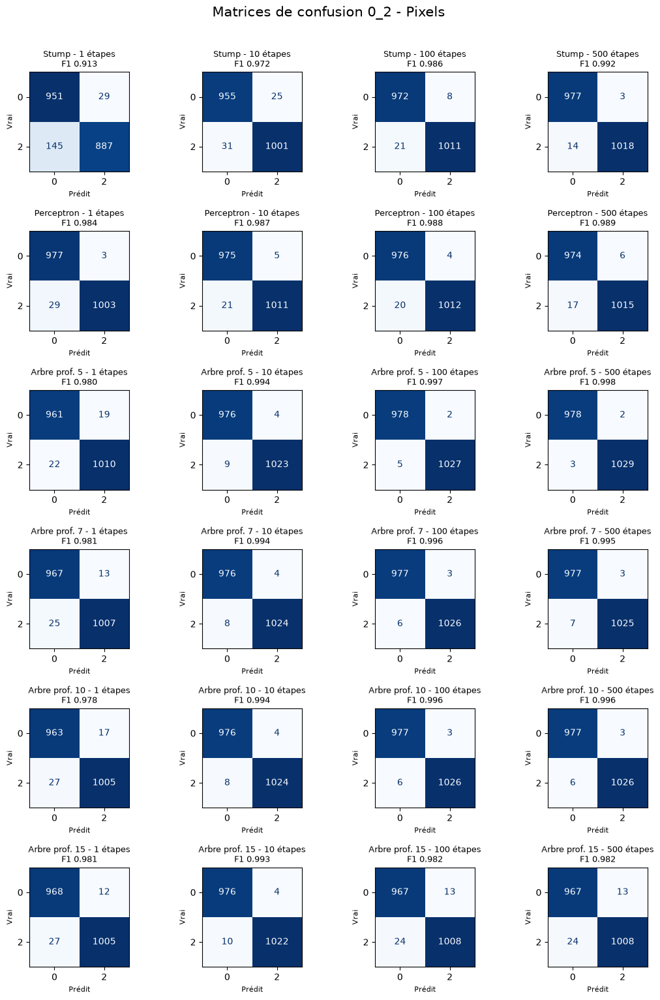

...

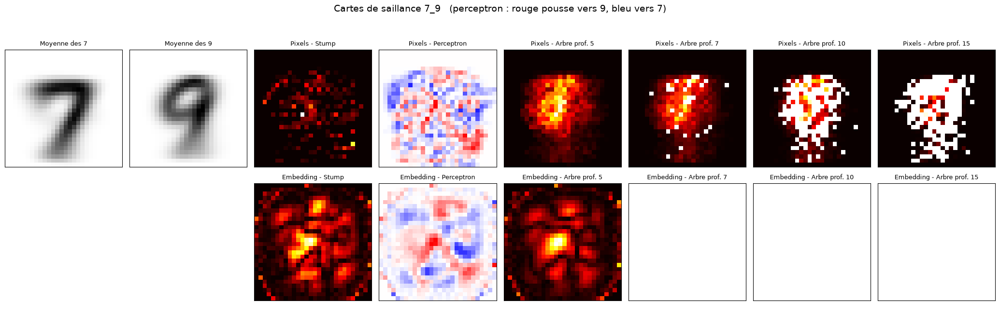

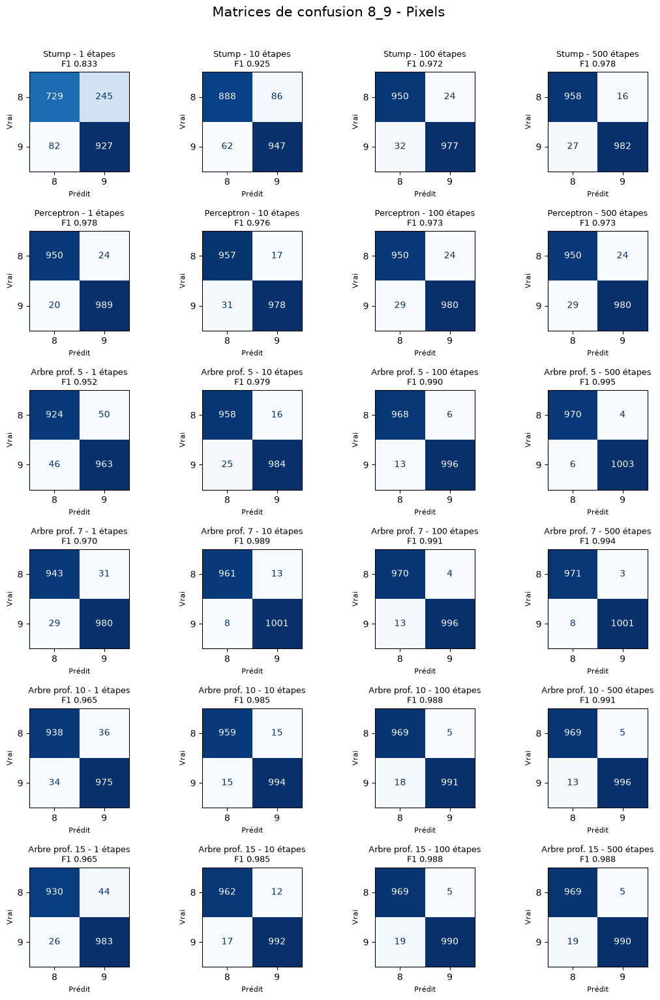

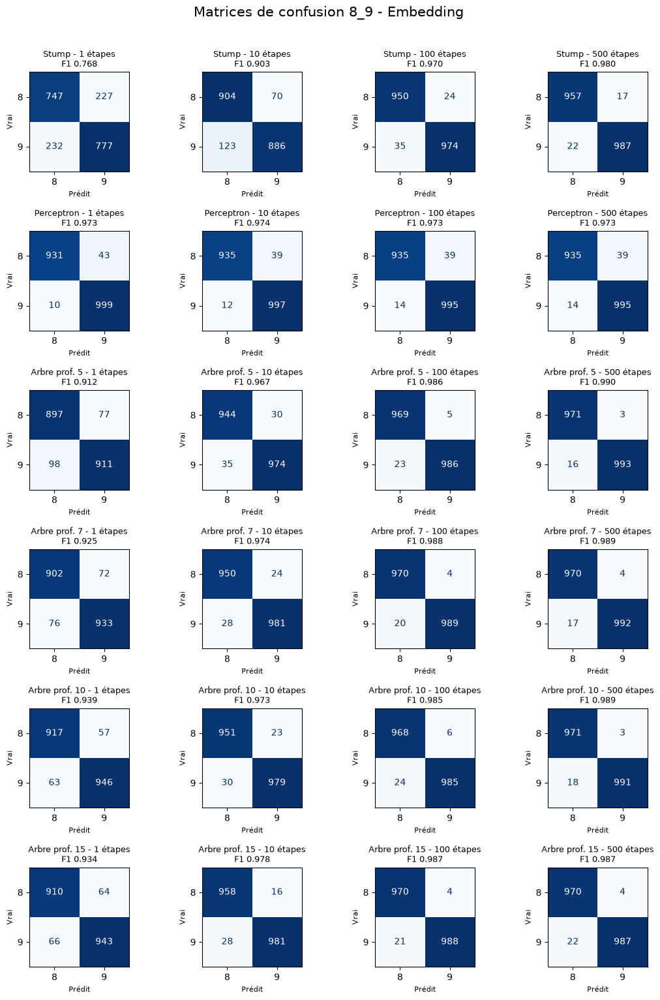

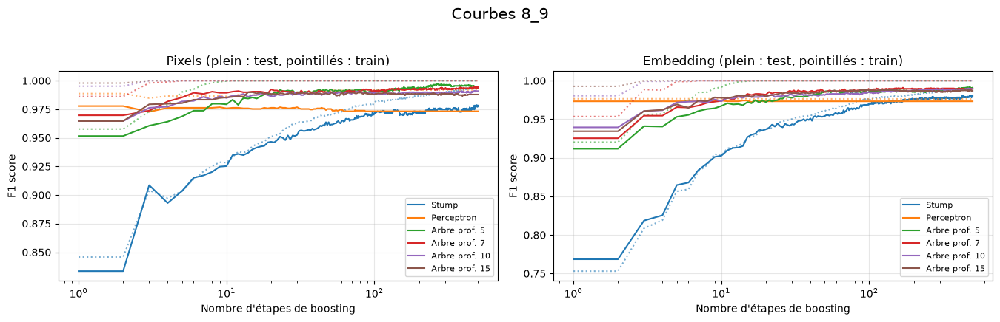

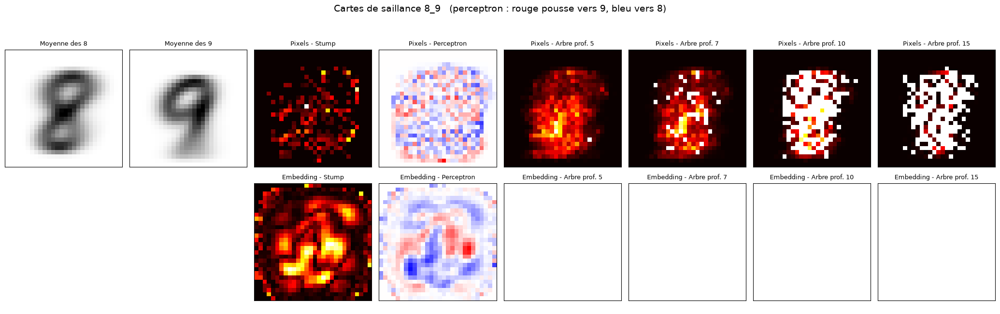

In [18]:
TACHES_A_AFFICHER = TACHES      # par exemple [t for t in TACHES if t["nom"] in ["3_8", "4_9"]]

for tache in TACHES_A_AFFICHER:
    for espace in ESPACES:
        figure_confusions(tache, espace)
    figure_courbes(tache)
    figure_saillance(tache)